# Model Training and Evaluation

This notebook trains, compares, and evaluates regression models on the retail dataset using a chronological train/test split.
Outputs are presented in both **tabular format** and **graphical format**.


In [1]:
# 1. Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')


In [2]:
# 2. Load and Merge Datasets
train_df = pd.read_csv('data/train.csv')
stores_df = pd.read_csv('data/stores.csv').rename(columns={'type': 'store_type'})
oil_df = pd.read_csv('data/oil.csv')
holidays_df = pd.read_csv('data/holidays_events.csv')
transactions_df = pd.read_csv('data/transactions.csv')

# Fill missing oil prices
oil_df['dcoilwtico'] = oil_df['dcoilwtico'].ffill().bfill()

# Clean holidays: keep non-transferred and deduplicate by date
holidays_clean = holidays_df[holidays_df['transferred'] == False].drop_duplicates(subset=['date']).rename(columns={'type': 'holiday_type'})

# Merge all datasets into df
df = train_df.merge(stores_df, on='store_nbr', how='left') \
             .merge(oil_df, on='date', how='left') \
             .merge(holidays_clean[['date', 'holiday_type']], on='date', how='left') \
             .merge(transactions_df, on=['date', 'store_nbr'], how='left')

# Fill missing values
df['holiday_type'] = df['holiday_type'].fillna('None')
df['transactions'] = df['transactions'].fillna(0)
df['dcoilwtico'] = df['dcoilwtico'].ffill().bfill()

print(f"Merged Dataset Shape: {df.shape}")
display(df.head())


Merged Dataset Shape: (3000888, 13)


,id,date,store_nbr,family,sales,onpromotion,city,state,store_type,cluster,dcoilwtico,holiday_type,transactions
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,93.14,Holiday,0.0
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,93.14,Holiday,0.0
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,93.14,Holiday,0.0
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,93.14,Holiday,0.0
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,93.14,Holiday,0.0


In [3]:
# 3. Feature Engineering: Extract date-based features
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['dayofweek'] = df['date'].dt.dayofweek
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

# Filter for 2017 data (reflects recent retail trends and trains quickly)
df_model = df[df['year'] == 2017].copy()
print(f"2017 Model Data Shape: {df_model.shape}")
display(df_model[['date', 'store_nbr', 'family', 'sales', 'onpromotion', 'month', 'day', 'dayofweek', 'is_weekend']].head())


2017 Model Data Shape: (404514, 18)


,date,store_nbr,family,sales,onpromotion,month,day,dayofweek,is_weekend
2596374,2017-01-01,1,AUTOMOTIVE,0.0,0,1,1,6,1
2596375,2017-01-01,1,BABY CARE,0.0,0,1,1,6,1
2596376,2017-01-01,1,BEAUTY,0.0,0,1,1,6,1
2596377,2017-01-01,1,BEVERAGES,0.0,0,1,1,6,1
2596378,2017-01-01,1,BOOKS,0.0,0,1,1,6,1


In [4]:
# 4. Select Features (X) and Target (y)
target = 'sales'
features = [
    'store_nbr', 'family', 'onpromotion', 'city', 'state', 'store_type', 
    'cluster', 'dcoilwtico', 'holiday_type', 'transactions', 
    'month', 'day', 'dayofweek', 'is_weekend'
]

# Encode categorical features with OrdinalEncoder
cat_cols = ['family', 'city', 'state', 'store_type', 'holiday_type']
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
df_model[cat_cols] = encoder.fit_transform(df_model[cat_cols])

X = df_model[features]
y = df_model[target]

print('Features (X):', features)
print('Target (y):', target)


Features (X): ['store_nbr', 'family', 'onpromotion', 'city', 'state', 'store_type', 'cluster', 'dcoilwtico', 'holiday_type', 'transactions', 'month', 'day', 'dayofweek', 'is_weekend']
Target (y): sales


In [5]:
# 5. Chronological Train / Test Split
# Train on earlier dates (< 2017-08-01), test on final 15 days (>= 2017-08-01)
train_mask = df_model['date'] < '2017-08-01'
test_mask = df_model['date'] >= '2017-08-01'

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print(f"Training Range: {df_model.loc[train_mask, 'date'].min().date()} to {df_model.loc[train_mask, 'date'].max().date()} ({X_train.shape[0]} samples)")
print(f"Testing Range:  {df_model.loc[test_mask, 'date'].min().date()} to {df_model.loc[test_mask, 'date'].max().date()} ({X_test.shape[0]} samples)")


Training Range: 2017-01-01 to 2017-07-31 (377784 samples)
Testing Range:  2017-08-01 to 2017-08-15 (26730 samples)


In [6]:
# 6. Train and Evaluate Algorithms
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=40, max_depth=12, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1, n_jobs=-1)
}

results = []
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    
    # Predict (sales cannot be negative)
    y_pred = np.clip(model.predict(X_test), 0, None)
    predictions[name] = y_pred
    
    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'R2 Score': round(r2, 4)
    })

# Tabular Format: Model Evaluation Comparison
results_df = pd.DataFrame(results).sort_values(by='RMSE', ascending=True).reset_index(drop=True)
print("\n=================== MODEL EVALUATION RESULTS (TABULAR FORMAT) ===================")
display(results_df)


Training Linear Regression...
Training Random Forest...
Training XGBoost...
Training LightGBM...

=================== MODEL EVALUATION RESULTS (TABULAR FORMAT) ===================


,Model,MAE,RMSE,R2 Score
0,XGBoost,103.27,278.49,0.9499
1,Random Forest,86.26,281.19,0.9489
2,LightGBM,109.66,290.37,0.9455
3,Linear Regression,423.92,1001.47,0.3522


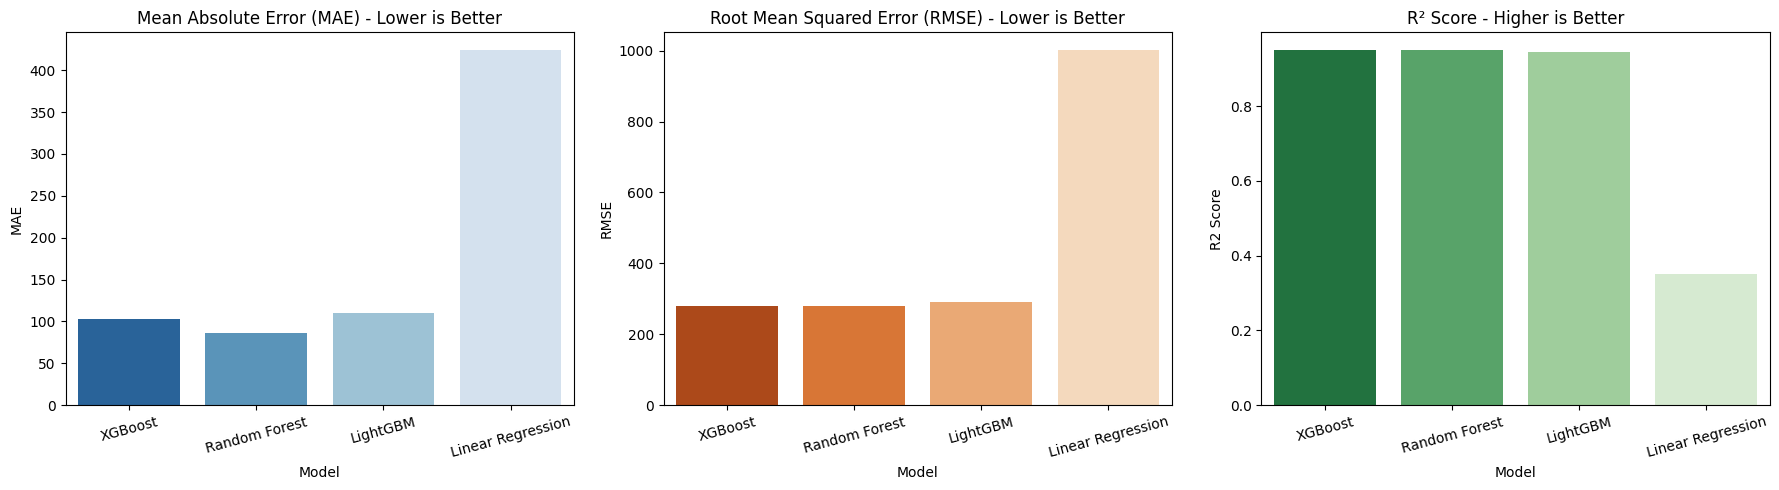

In [7]:
# 7. Graphical Format: Model Evaluation Comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=results_df, x='Model', y='MAE', ax=axes[0], palette='Blues_r')
axes[0].set_title('Mean Absolute Error (MAE) - Lower is Better')
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(data=results_df, x='Model', y='RMSE', ax=axes[1], palette='Oranges_r')
axes[1].set_title('Root Mean Squared Error (RMSE) - Lower is Better')
axes[1].tick_params(axis='x', rotation=15)

sns.barplot(data=results_df, x='Model', y='R2 Score', ax=axes[2], palette='Greens_r')
axes[2].set_title('R² Score - Higher is Better')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


In [8]:
# 8. Tabular Format: Difference between Actual and Predicted Values
best_model_name = results_df.iloc[0]['Model']
best_preds = predictions[best_model_name]

pred_df = pd.DataFrame({
    'Actual Value': y_test.values,
    'Predicted Value': np.round(best_preds, 2),
    'Difference': np.round(y_test.values - best_preds, 2)
})

print(f"\n=================== ACTUAL VS PREDICTED DIFFERENCE ({best_model_name}) ===================")
display(pred_df.head(25))

print("\n--- Summary Statistics of Difference (Residuals) ---")
display(pred_df['Difference'].describe())



=================== ACTUAL VS PREDICTED DIFFERENCE (XGBoost) ===================


,Actual Value,Predicted Value,Difference
0,5.00000,5.680000,-0.68
1,0.00000,5.680000,-5.68
2,4.00000,5.680000,-1.68
3,2627.00000,3187.479980,-560.48
4,0.00000,18.760000,-18.76
5,373.70898,302.190002,71.52
6,11.00000,39.130001,-28.13
7,867.00000,1065.800049,-198.80
8,668.00000,621.150024,46.85
9,133.58800,308.709991,-175.12



--- Summary Statistics of Difference (Residuals) ---


count    26730.000000
mean       -21.636502
std        277.657714
min      -4635.620000
25%        -42.877500
50%         -8.410000
75%          6.000000
max       7101.550000
Name: Difference, dtype: float64

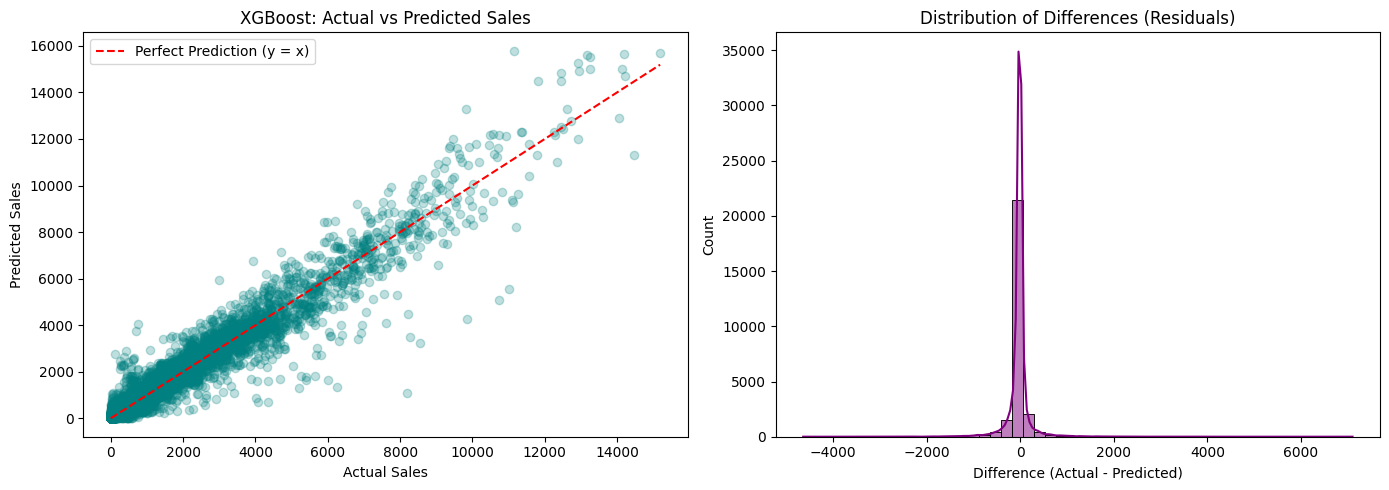

In [9]:
# 9. Graphical Format: Actual vs Predicted & Error Distribution
plt.figure(figsize=(14, 5))

# Scatter Plot: Actual vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test.values, best_preds, alpha=0.25, color='teal')
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--', label='Perfect Prediction (y = x)')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title(f'{best_model_name}: Actual vs Predicted Sales')
plt.legend()

# Distribution of Error Differences
plt.subplot(1, 2, 2)
sns.histplot(pred_df['Difference'], bins=50, kde=True, color='purple')
plt.xlabel('Difference (Actual - Predicted)')
plt.title('Distribution of Differences (Residuals)')

plt.tight_layout()
plt.show()
